# Автоматическое распознавание вида модуляции и оценка параметров радиосигналов методами ML

**Главный ноутбук проекта** — сводка всей работы: цели, поэтапное описание, промежуточные выводы, итоги.
Подробности, код и статистика каждого этапа — в ноутбуках `00`–`05` (ссылки в каждом разделе); здесь собраны
ключевые результаты (читаются из сохранённых метрик, без переобучения) и демонстрация готового продукта.

## Цели и задачи
**Цель** — по записи радиосигнала определять **вид модуляции** (11 классов: 8PSK, AM-DSB, AM-SSB, BPSK, CPFSK,
GFSK, PAM4, QAM16, QAM64, QPSK, WBFM) и **параметры сигнала** (ОСШ, несущая, полоса, символьная скорость,
roll-off, разнос частот ЧМн) и довести модель до работающего продукта.

**Задачи:**
1. изучить открытые датасеты и их качество;
2. построить собственный генератор сигналов с реалистичным каналом и полными метками;
3. baseline на экспертных признаках со статистической проверкой значимости;
4. нейросети на сырых I/Q, абляции, статистическое сравнение;
5. оценка параметров: классическая ЦОС против многозадачной нейросети;
6. ансамбль, перенос между датасетами, устойчивость, выбор модели;
7. продукт (ONNX, CLI, REST API, веб-интерфейс, Docker) и его сквозная проверка.

**Почему это задача ML.** Классические методы распознавания (дерево решений по кумулянтам, правдоподобие)
требуют точной модели канала и ломаются при многолучёвости и сдвиге частоты; методы ML учатся на данных с такими
искажениями. Метрика — accuracy (классы сбалансированы) и её зависимость от ОСШ; для параметров — медиана
абсолютной ошибки (устойчива к единичным срывам оценщиков).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
DEEP = ROOT / "models" / "deep"


def show(path: str, width: int = 900) -> None:
    """Показать сохранённый рисунок этапа."""
    display(Image(filename=str(FIG / path), width=width))


def metrics(run: str) -> dict:
    """Метрики запуска нейросети (models/deep/<run>/metrics.json)."""
    return json.loads((DEEP / run / "metrics.json").read_text(encoding="utf-8"))["metrics"]

## Этап 1. Данные и EDA (`01_eda`)
- **RadioML 2016.10a** (DeepSig): 220 000 окон по 128 отсчётов I/Q, 11 классов, ОСШ −20…18 дБ — стандарт
  литературы. Загружен с зеркала HuggingFace **безопасным** загрузчиком pickle (только типы numpy).
- **Panoradio HF**: 18 КВ-режимов, канал Ваттерсона (расширение, EDA).

**Промежуточные выводы EDA:** дублей нет; мощность не нормирована → нормировка на входе. Найдены **дефекты
RadioML**: AM-SSB — чистый шум при любом ОСШ (спектральная плоскостность 0,564 = шум 0,565), AM-DSB — почти
немодулированная несущая (глубина ≈ 2 %), WBFM — тон в 95 % примеров. Следствие: часть accuracy в литературе —
артефакт (при низком ОСШ модель «угадывает» AM-SSB, называя шумом всё подряд), поэтому метрики приводятся и
без AM-SSB, а для продукта нужен свой датасет.

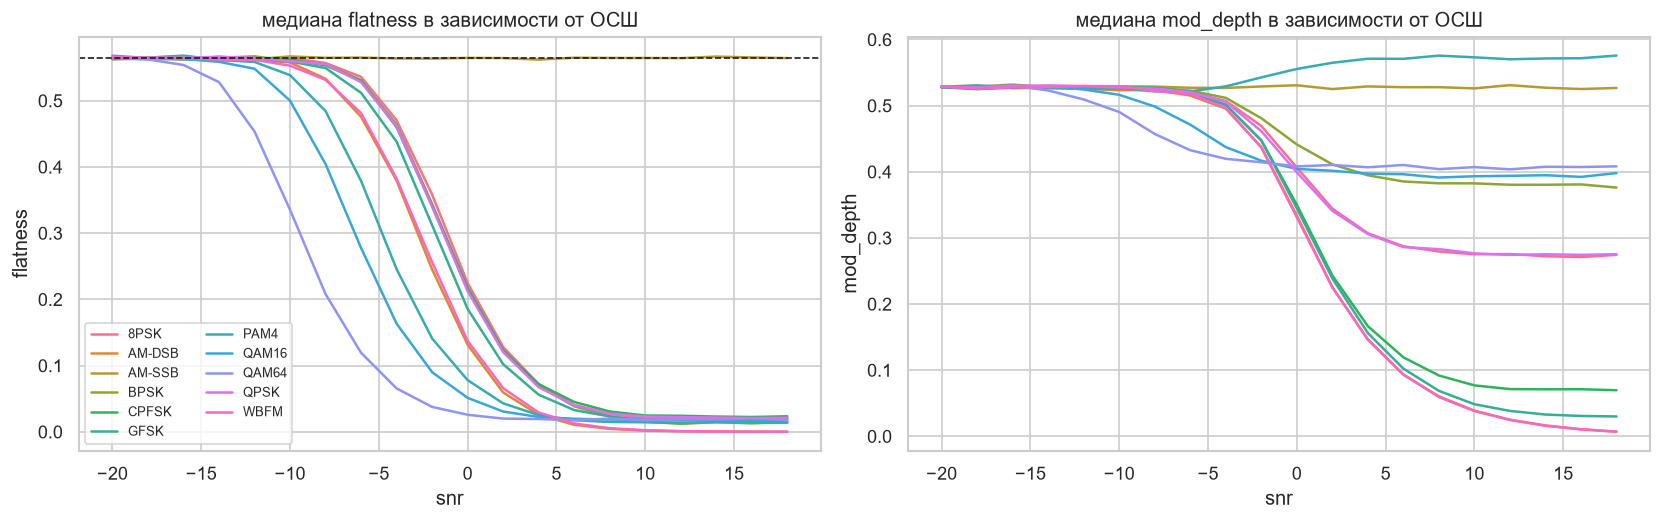

In [2]:
show("eda/flatness_depth.png")

## Этап 0. Собственный генератор (`00_generator`)
`src/amc/generator.py`: те же 11 классов; непрерывное время (дробное число отсчётов на символ 4–16), RRC с
roll-off 0,2–0,5, CPFSK/GFSK с индексом 0,4–1,0, АМ/SSB/ЧМ с реальным модулирующим спектром; канал — 1–4 луча
Рэлея/Райса с доплером, фазовый шум, сдвиг частоты ±0,05 fs, ошибка тактовой частоты ±100 ppm; ОСШ −20…20 дБ.
**Все параметры записываются в метаданные** — это метки для оценки параметров. 220 000 окон × 1024 отсчёта
генерируются за ≈ 40 с (параллельно, с контролем памяти).

**Промежуточный вывод:** при первой версии найден «обходной» признак — аналоговые классы всегда были уже
цифровых, модель могла классифицировать по ширине полосы. Диапазон полосы звука расширен, датасет пересоздан —
полосы классов перекрываются (рисунок).

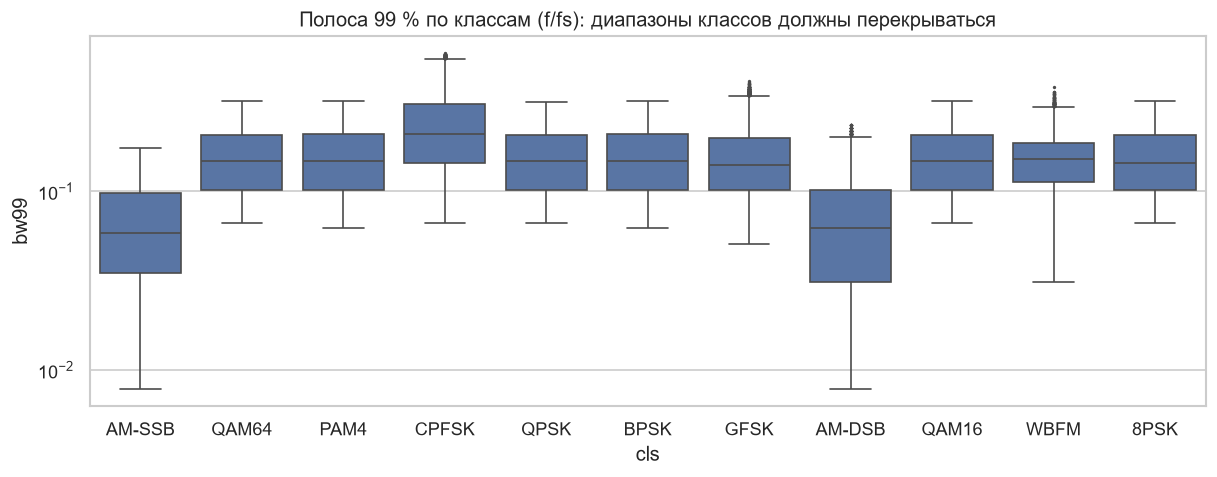

In [3]:
show("generator/bw_by_class.png", 800)

## Этап 2. Признаки и baseline (`02_features_baseline`)
26 экспертных признаков: кумулянты C20–C63, признаки Азаз–Нанди (γmax, σap, σdp, σaa, σaf), спектральные линии
z^M, спектр огибающей. Значимость — Краскел–Уоллис с размером эффекта ε², корреляции Спирмена, попарный
тест Данна (поправка Холма). Модели: LogReg, RandomForest, LightGBM (подбор гиперпараметров Optuna).

**Промежуточные выводы:** LightGBM — 54,8 % на RadioML (ОСШ ≥ 0: 83,7 %), 51,4 % на своём (75,3 %); значимо
лучше логистической регрессии (Мак-Немар p ≈ 1e-94). Отбор признаков по ε² ухудшил val — используются все;
главный признак по SHAP — эксцесс спектра. QAM16/QAM64 по признакам различимы слабо (ε² 0,2–0,36).

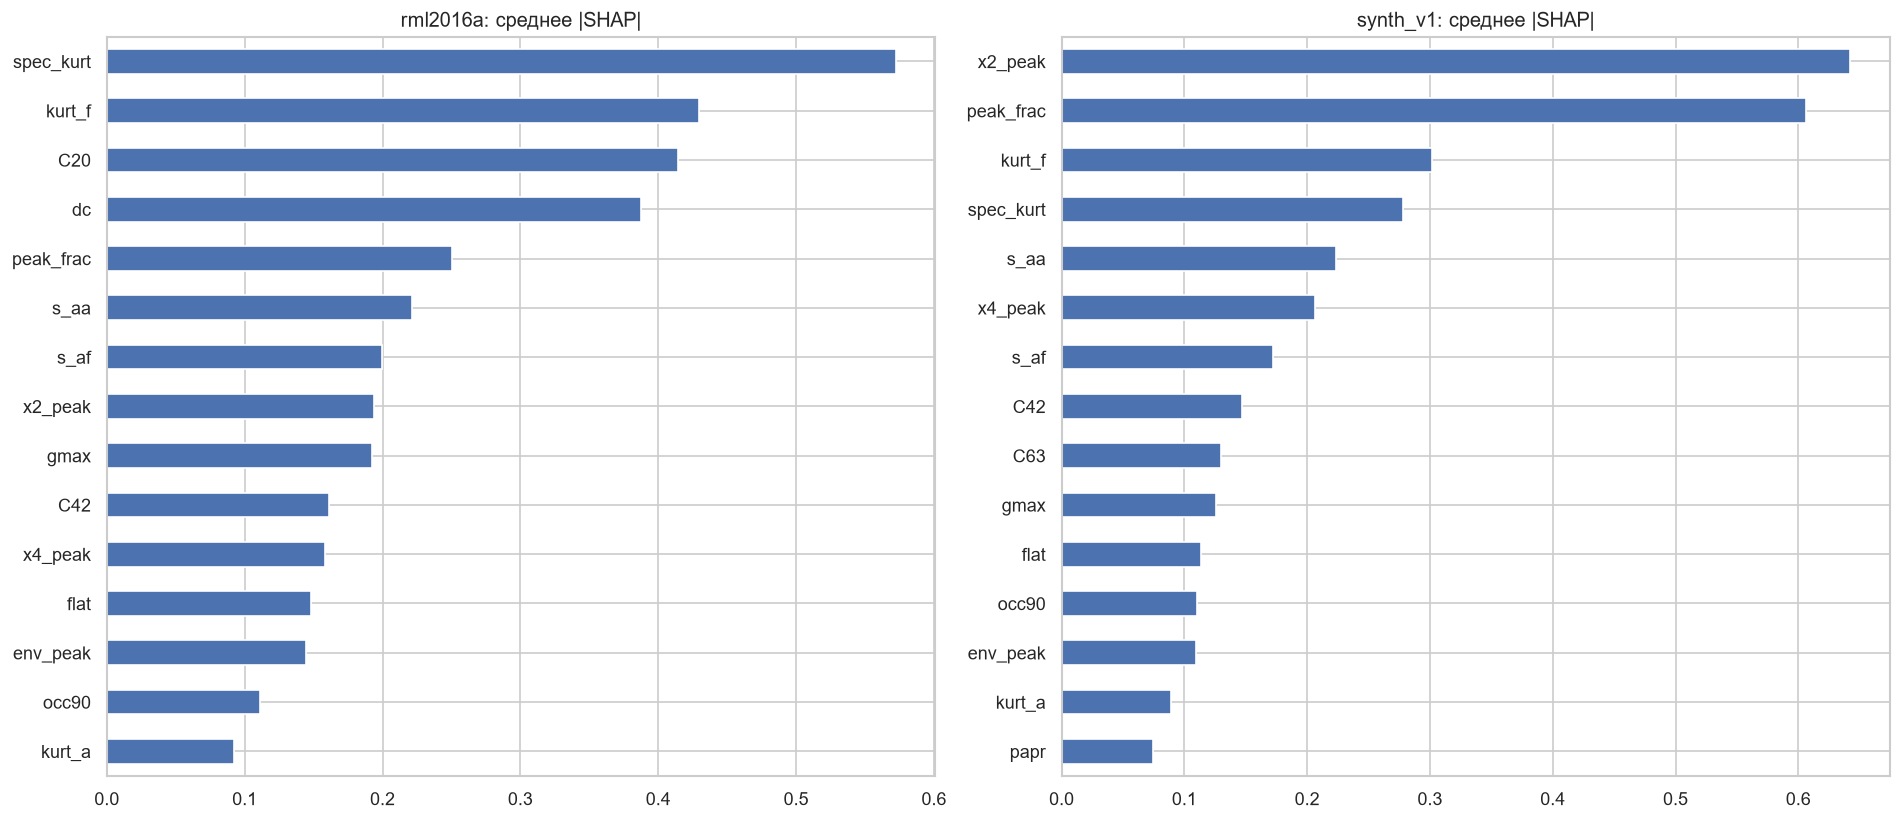

In [4]:
show("baseline/shap.png", 700)

## Этап 3. Нейросети (`03_deep_models`)
VT-CNN2 (из литературы), ResNet-1D, CNN-LSTM; вход — I/Q, нормированные по мощности; аугментации на GPU
(поворот фазы, сдвиг частоты, инверсия спектра); AdamW + OneCycle, bf16, ранняя остановка; 3 seed'а; MLflow.

In [5]:
rows = []
for name, run_rml, run_syn in [("VT-CNN2", "rml2016a_vtcnn2_iq_aug_s{}", None),
                               ("ResNet-1D", "rml2016a_resnet_iq_aug_s{}", "synth_v1_resnet_iq_aug_s{}"),
                               ("CNN-LSTM", "rml2016a_cnnlstm_iq_aug_s{}", "synth_v1_cnnlstm_iq_aug_s{}_e60")]:
    r = {"модель": name}
    for col, tpl in [("RadioML", run_rml), ("свой (1024)", run_syn)]:
        if tpl is None:
            continue
        m = [metrics(tpl.format(s)) for s in range(3)]
        acc = np.array([x["test_acc"] for x in m])
        r[f"{col}: acc"] = f"{acc.mean():.1%} ± {acc.std(ddof=1):.1%}"
        r[f"{col}: ОСШ≥0"] = f"{np.mean([x['test_acc_snr>=0'] for x in m]):.1%}"
    rows.append(r)
rows.insert(0, {"модель": "LightGBM (признаки)", "RadioML: acc": "54.8%", "RadioML: ОСШ≥0": "83.7%",
                "свой (1024): acc": "51.4%", "свой (1024): ОСШ≥0": "75.3%"})
pd.DataFrame(rows).set_index("модель").fillna("—")

,RadioML: acc,RadioML: ОСШ≥0,свой (1024): acc,свой (1024): ОСШ≥0
модель,,,,
LightGBM (признаки),54.8%,83.7%,51.4%,75.3%
VT-CNN2,50.6% ± 0.4%,74.8%,—,—
ResNet-1D,61.7% ± 0.1%,91.5%,59.4% ± 0.3%,86.7%
CNN-LSTM,62.0% ± 0.3%,91.7%,62.9% ± 0.1%,88.4%


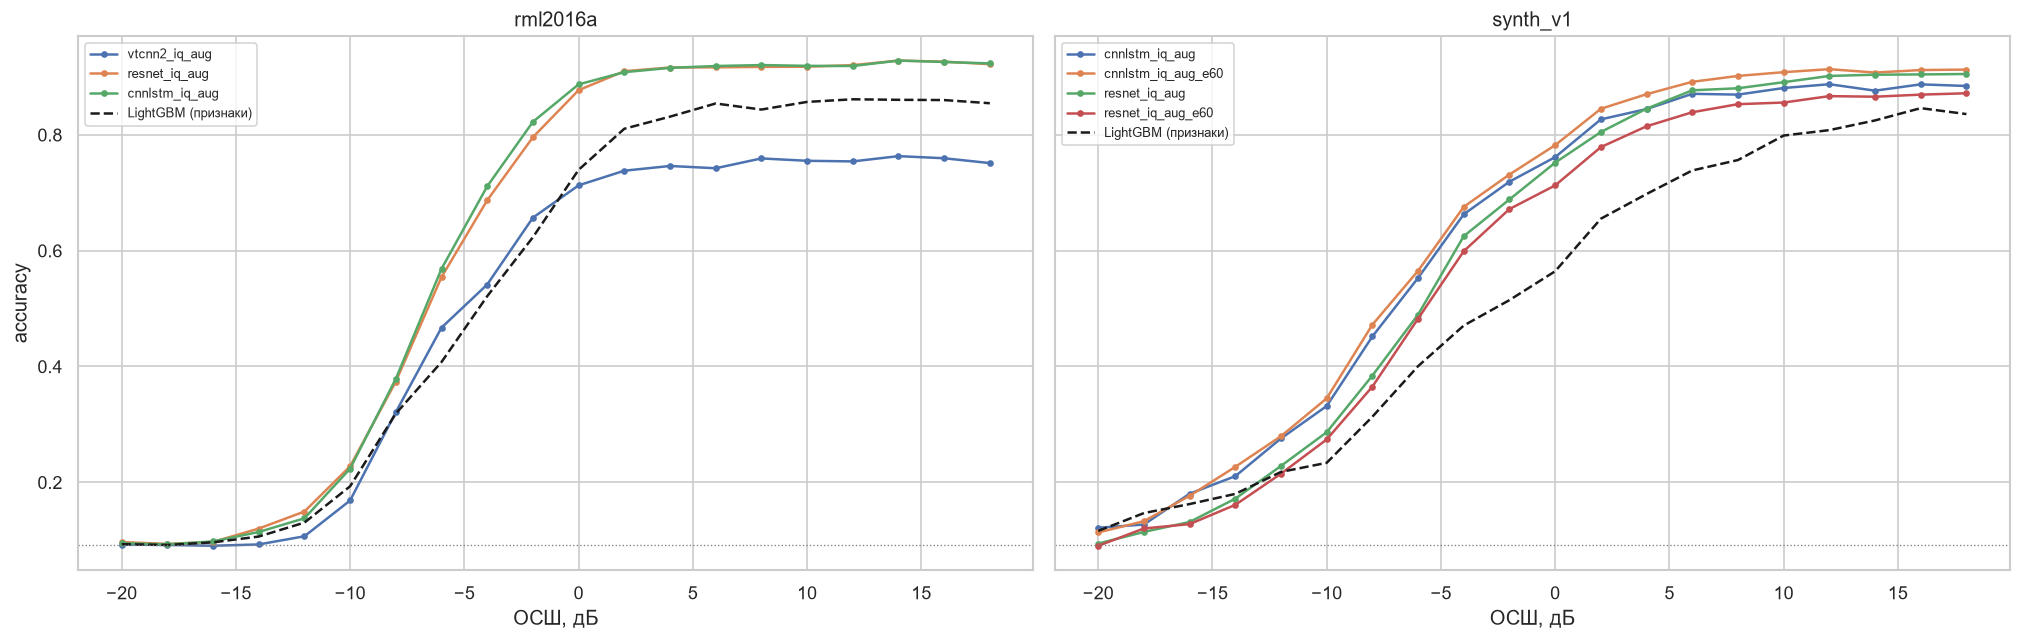

In [6]:
show("deep/acc_vs_snr.png")

**Промежуточные выводы:**
- нейросети значимо лучше признаков: +7,2 п.п. на RadioML (ДИ 95 % [6,9; 7,6], Мак-Немар p < 1e-300),
  +11,5 п.п. на своём; результат на RadioML (62 %) соответствует литературе;
- VT-CNN2 хуже бустинга — архитектура важнее размера: CNN-LSTM (0,28 млн параметров) лучшая на обоих датасетах;
- аугментации +1,2 п.п. (p = 6e-12) и устойчивость к искажениям; вход амплитуда+частота хуже I/Q;
- длинное обучение помогает только малой модели: ResNet при бюджете 60 эпох переобучается (−2 п.п.),
  CNN-LSTM выигрывает +1,7 п.п. — выбор моделей только по val;
- остаточные ошибки: QAM16 ↔ QAM64, QPSK → 8PSK (свой), WBFM → AM-DSB (дефект RadioML).

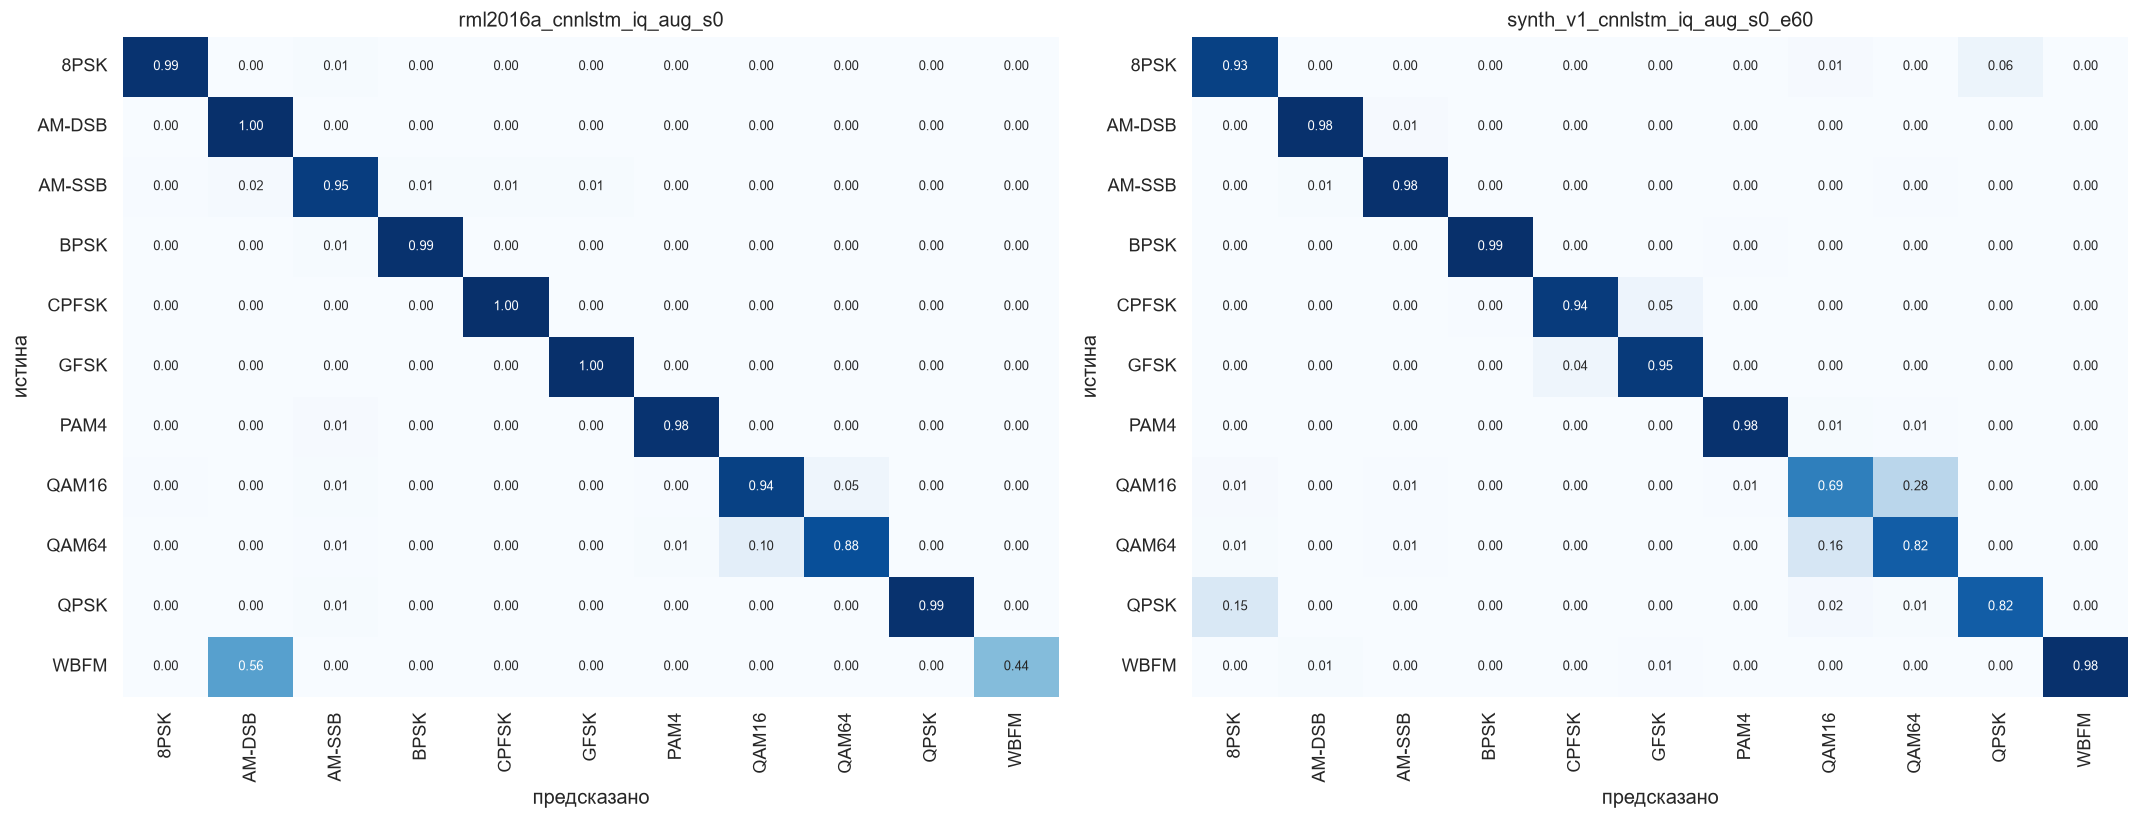

In [7]:
show("deep/confusion_best.png")

## Этап 3b. Оценка параметров (`03b_parameters`)
Многозадачная сеть (общий энкодер, голова классификации + голова регрессии 6 параметров, маскированная функция
потерь Хьюбера) против классических оценщиков ЦОС (`src/amc/estimators.py`: спектральная оценка ОСШ и M2M4,
линия z^M и центр тяжести спектра для сдвига частоты, линия спектра огибающей и |Δf| для скорости, полоса 99 %
по спектру Уэлча и т.д.). Сравнение — критерий Уилкоксона для парных ошибок.

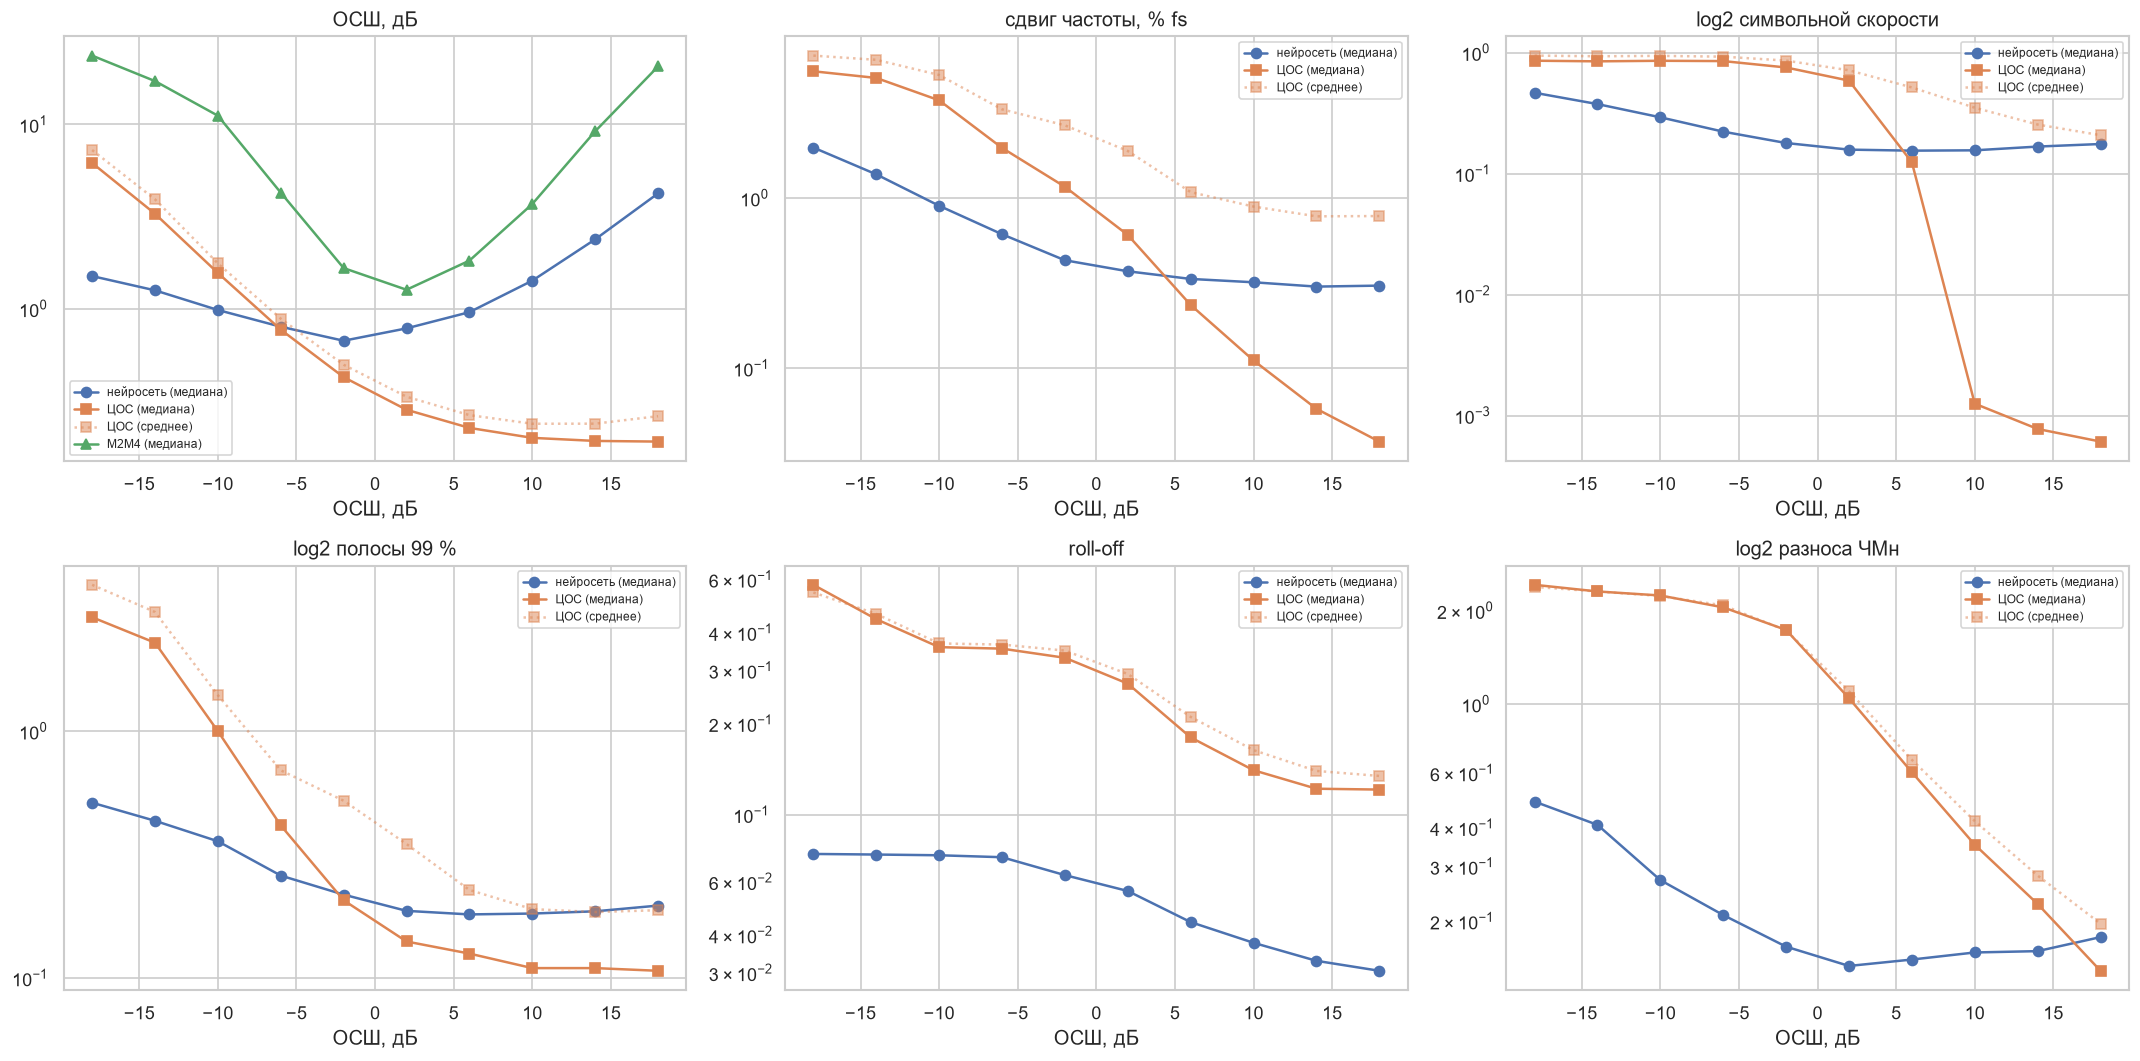

In [8]:
show("parameters/errors_vs_snr.png")

**Промежуточные выводы:** при ОСШ > 0 ЦОС на порядок точнее (ОСШ 0,21 дБ против 1,66; скорость 0,13 % против
12 %); при ОСШ < 0 точнее сеть по всем параметрам; roll-off и разнос ЧМн сеть оценивает лучше всегда.
**Гибрид** (метод выбирается на val по интервалу ОСШ, оценённого сетью) — лучший или равный лучшему почти
везде. ML не заменяет ЦОС, а дополняет её.

## Этап 4. Ансамбль, перенос, устойчивость (`04_analysis`)
- **Stacking** (логрегрессия на вероятностях LightGBM + ResNet + CNN-LSTM, обучена на val): свой датасет
  **65,1 %** (ОСШ ≥ 0: 90,8 %) против 62,9 % у лучшей одиночной; RadioML 62,75 % против 62,0 %; значимо.
- **Перенос:** модели RadioML на своём датасете — 13 % (угадывание), модель своего генератора на RadioML — 45 %
  (73 % при ОСШ ≥ 10 дБ) → свой генератор обоснован.
- **Устойчивость:** без аугментаций инверсия спектра стоит 15 п.п.; модели RadioML ломаются при сдвиге частоты
  ≥ 0,01 fs (вне обучающего диапазона); главный фактор ошибок в канале — многолучёвость (95 % → 84 %).

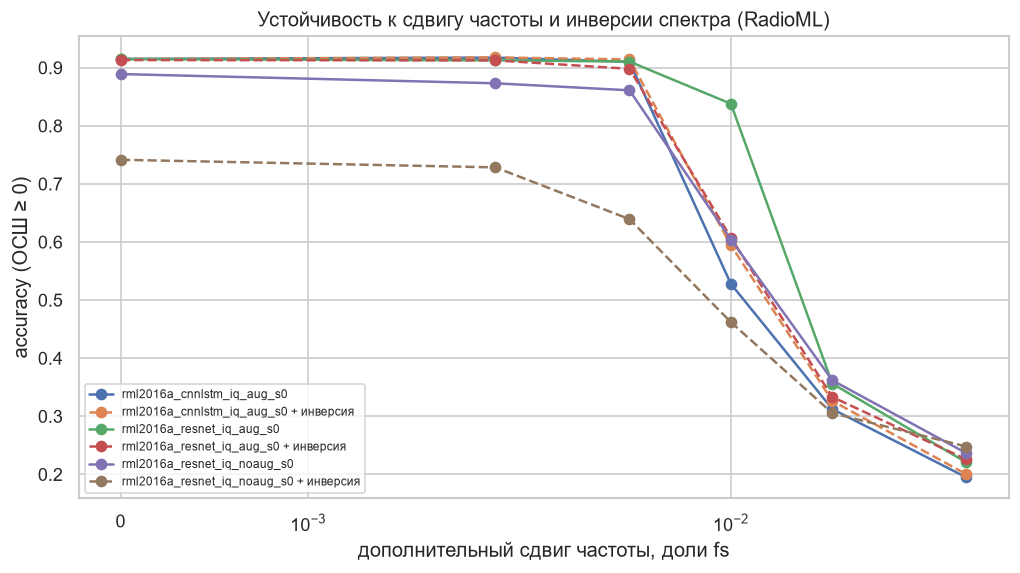

In [9]:
show("analysis/robust_cfo.png", 800)

**Выбор финальной модели:** многозадачная ResNet-1D (лучшая по val) — она одна даёт класс и все параметры,
необходимые для перевода в физические единицы и гибрида с ЦОС; экспортирована в ONNX (5 МБ, расхождение с
PyTorch ≤ 4e-6, на CPU быстрее PyTorch). Stacking точнее по классу, но требует трёх моделей — это направление
развития продукта.

## Этап 5. Продукт и его сквозная проверка (`05_product`)
`src/amc/infer.py` (CLI `python -m amc.infer`), `app/api.py` (FastAPI, Swagger), `app/streamlit_app.py`,
`Dockerfile` (без torch, только ONNX Runtime). Конвейер: WAV любого формата (моно — вещественный сигнал,
стерео — I/Q) → поиск сигнала по спектру → перенос в ноль и передискретизация до занятости полосы ≈ 15 % →
окна 1024 → сеть → поиск масштаба по самосогласованности → агрегация → гибрид с ЦОС → Гц, Бод, дБ.

In [10]:
D = pd.read_csv(ROOT / "reports" / "product_eval.csv")
print(f"сквозная проверка: {len(D)} WAV-файлов, accuracy {D['верно'].mean():.1%}")
D.groupby(pd.cut(D["snr_inband"], [0, 5, 10, 15, 20, 25]), observed=True)["верно"].mean().rename(
    "accuracy по ОСШ в полосе, дБ").to_frame().T.round(3)

сквозная проверка: 440 WAV-файлов, accuracy 75.2%


snr_inband,"(0, 5]","(5, 10]","(10, 15]","(15, 20]","(20, 25]"
"accuracy по ОСШ в полосе, дБ",0.397,0.658,0.83,0.896,0.9


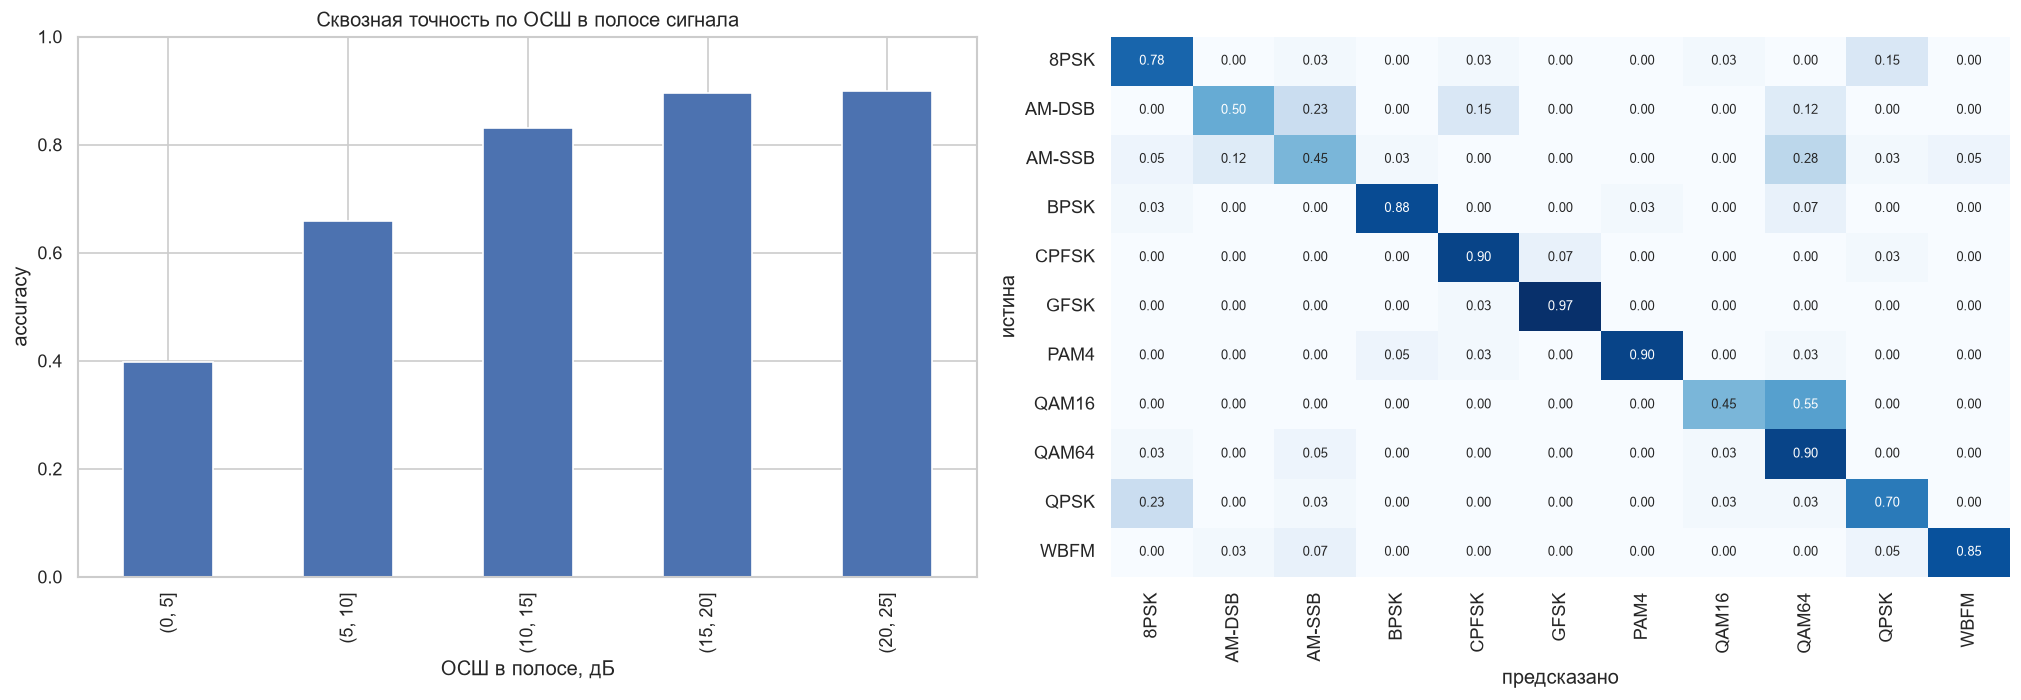

In [11]:
show("product/product_accuracy.png")

**Промежуточные выводы:** сквозная точность 75,2 % (83–90 % при ОСШ ≥ 10 дБ в полосе), что близко к точности
модели на её собственном тесте в тех же условиях — потери конвейера малы. Сквозная проверка нашла две ошибки
конвейера, невидимые на тесте окон (моно-файлы: 20 % → 72 %; АМ с малой глубиной), — обе исправлены.
Параметры: несущая — медиана ошибки 9 Гц, ОСШ — 1,4 дБ, полоса — 8 %, roll-off — 0,04; символьная скорость —
медиана 4,6 % (каскад «сеть даёт грубую оценку → линия ЦОС уточняет»; при хорошем ОСШ — точнее 0,1 %).

### Демонстрация продукта
Анализ WAV-файлов с известными параметрами (`tools/make_test_wavs.py`: fs 48 кГц, несущая ≈ 9 кГц,
ОСШ 15 дБ в полосе сигнала).

In [12]:
from amc.infer import Classifier, analyze  # noqa: E402

wav_dir = ROOT / "data" / "test_wavs"
if (wav_dir / "truth.csv").exists():
    truth = pd.read_csv(wav_dir / "truth.csv").set_index("cls")
    clf = Classifier()
    demo = []
    for cls in truth.index:
        r = analyze(wav_dir / f"{cls}_iq.wav", clf)
        t = truth.loc[cls]
        demo.append({"истина": cls, "распознано": r["modulation"], "уверенность": round(r["confidence"], 2),
                     "несущая (истина / оценка), Гц": f"{t.carrier_Hz:.0f} / {r['carrier_Hz']:.0f}",
                     "скорость (истина / оценка), Бод": (f"{t.symbol_rate_Bd:.0f} / {r['symbol_rate_Bd']:.0f}"
                                                         if r["symbol_rate_Bd"] and t.symbol_rate_Bd == t.symbol_rate_Bd
                                                         else "—"),
                     "полоса (истина / оценка), Гц": f"{t.bw99_Hz:.0f} / {r['bandwidth99_Hz']:.0f}"})
    display(pd.DataFrame(demo).set_index("истина"))
else:
    print("тестовые WAV не созданы: python tools/make_test_wavs.py data/test_wavs")

,распознано,уверенность,"несущая (истина / оценка), Гц","скорость (истина / оценка), Бод","полоса (истина / оценка), Гц"
истина,,,,,
8PSK,8PSK,0.80,8961 / 8988,1265 / 1353,1406 / 1348
AM-DSB,AM-SSB,0.49,8914 / 9172,—,1500 / 144
AM-SSB,WBFM,0.69,9052 / 8955,—,234 / 164
BPSK,BPSK,1.00,9011 / 9011,1840 / 1840,2062 / 1969
CPFSK,CPFSK,1.00,9051 / 9069,1976 / 2095,3844 / 2355
GFSK,GFSK,0.98,8933 / 8922,1304 / 1428,1406 / 1336
PAM4,PAM4,1.00,9092 / 9092,1807 / 1806,2156 / 2051
QAM16,QAM16,0.57,8946 / 8946,1942 / 1942,2344 / 2250
QAM64,QAM64,0.58,9013 / 9013,1580 / 1580,1875 / 1816


## Итоги
1. **Задача решена:** модель распознаёт 11 видов модуляции с точностью 62–63 % в среднем по всему диапазону
   ОСШ −20…20 дБ и 88–92 % при ОСШ ≥ 0 дБ (на уровне лучших результатов литературы для RadioML 2016.10a);
   ансамбль — 65,1 % / 90,8 %.
2. **Оценка параметров:** многозадачная сеть + классическая ЦОС в гибриде; гибрид лучше каждого метода
   по отдельности; проверено статистически (Уилкоксон).
3. **Данные:** найдены и количественно описаны дефекты популярного датасета RadioML 2016.10a; написан
   генератор с реалистичным каналом; показано, что модели RadioML не переносятся на реалистичные данные
   (13 %), а модели своего генератора переносятся на RadioML (45 % / 73 % при ОСШ ≥ 10 дБ).
4. **Продукт:** CLI, REST API, веб-интерфейс, Docker; работает на WAV с произвольной частотой дискретизации,
   несущей и форматом; сквозная точность 75 % (до 90 % при хорошем ОСШ).
5. **Инженерия:** 77 автотестов (pytest), линтер (ruff), CI (GitHub Actions), MLflow, фиксированные seed'ы и версии
   пакетов; все решения о выборе моделей приняты по val, тест — только для итоговой оценки.

**Ограничения и развитие:** нет эквалайзера — QAM16/QAM64 при многолучёвости различаются плохо (22 %);
АМ при сильном шуме и малой глубине модуляции неотличима от тона (в демонстрации ниже AM-DSB распознан как
AM-SSB, AM-SSB — как WBFM: сквозная точность этих классов 45–50 %); скорость ЧМн оценивается грубо (≈ 10 %).
Следующие шаги: адаптивный эквалайзер перед сетью, режим «ансамбль» в продукте, дообучение на записях реального
эфира, расширение классов (КВ-режимы Panoradio).